In [1]:

import matplotlib.gridspec as gridspec
import os
import sys

import umap

from BWM.Notebooks.DensMAPHyperparameters import n_neighbors

active_lambda = 0.1 # Default value if not imported
sys.path.append(os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [60]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    #row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    #X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_transposed


# directory_path='../Data2'
# eids = [d for d in os.listdir(directory_path) if os.path.isdir(os.path.join(directory_path, d))]
# result = get_region_response_matrix(
#                 region=['MOs','MOp'],
#                 eids=eids,
#                 directory_path=directory_path,
#                 event="stimOn_times",
#                 conditions=['choice'],
#                 n_pseudo=25,
#                 threshold=1,
#                 std_above=50,
#                 std_below=50,
#                 filter_significant=False,
#                 n_steps=100,
#                 step=0.01,
#                 sigma=2,
#                 mapping='Beryl'
#             )
# pseudo_response_tensor =result[0]
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]



In [40]:
# selected_eid = '6274dda8-3a59-4aa1-95f8-a8a549c46a26' # Example EID
# directory_path = '../Data2'
# event = 'stimOn_times'
# conditions = ['choice']
#
# result = get_eid_response_matrix(
#     selected_eid, directory_path, event, conditions,
#     n_pseudo=25,
#     threshold = 0,
#     filter_significant=False,
#     n_steps=100, step=0.01 , sigma=2,
# )
#
#
# pseudo_response_tensor, common_conditions, beryl_regions, cosmos_regions, cluster_ids = result


In [61]:
def trial_variability(x):

    z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))
    return (
        np.mean(np.std(z, axis=0),axis=(0,1)))

variability = trial_variability(pseudo_response_tensor)
pseudo_response_tensor=pseudo_response_tensor[:,:,:,variability<.7]

X_input = iso_ae_preprocessing(pseudo_response_tensor)


In [62]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    speed= np.mean(np.abs(np.diff(z,axis=1)),axis=(0,1))

    return speed

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

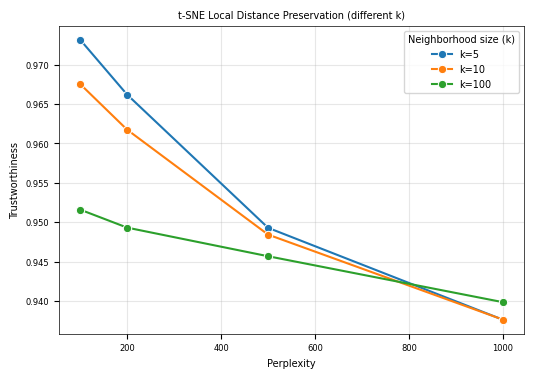

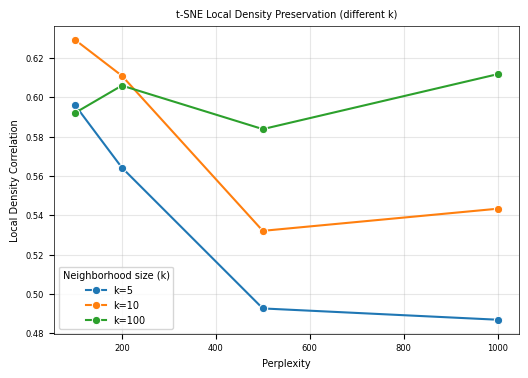

In [77]:
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from scipy.stats import pearsonr

def calculate_local_density(X, k=10):
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X)
    distances, _ = nn.kneighbors(X)
    return np.mean(distances, axis=1)

perplexities = [100,200,500,1000]
k_values = [5, 10,100]
trust_scores = {k: [] for k in k_values}
density_corrs = {k: [] for k in k_values}

# Pre-calculate local densities in high-dimensional space for all k
high_dim_densities = {k: calculate_local_density(X_input, k=k) for k in k_values}

for p in perplexities:
    x_proj_p = TSNE(perplexity=p, random_state=42).fit_transform(X_input)
    
    # Trustworthiness for different values of k
    for k in k_values:
        t = trustworthiness(X_input, x_proj_p, n_neighbors=k)
        trust_scores[k].append(t)
    
    # Local density correlation for different values of k
    for k in k_values:
        low_dim_density = calculate_local_density(x_proj_p, k=k)
        corr, _ = pearsonr(high_dim_densities[k], low_dim_density)
        density_corrs[k].append(corr)

# Updated plot for Trustworthiness with multiple curves for k
plt.figure(figsize=(6, 4))
for k in k_values:
    sns.lineplot(x=perplexities, y=trust_scores[k], marker='o', label=f'k={k}')

plt.xlabel('Perplexity')
plt.ylabel('Trustworthiness')
plt.title('t-SNE Local Distance Preservation (different k)')
plt.legend(title='Neighborhood size (k)')
plt.grid(True, alpha=0.3)
plt.show()

# Updated plot for Local Density Preservation with multiple curves for k
plt.figure(figsize=(6, 4))
for k in k_values:
    sns.lineplot(x=perplexities, y=density_corrs[k], marker='o', label=f'k={k}')

plt.xlabel('Perplexity')
plt.ylabel('Local Density Correlation')
plt.title('t-SNE Local Density Preservation (different k)')
plt.legend(title='Neighborhood size (k)')
plt.grid(True, alpha=0.3)
plt.show()

MSD before denoising (mean over neurons): 0.1325
MSD after denoising (mean over neurons): 0.0424


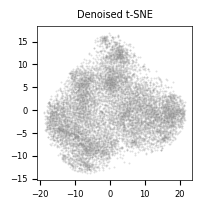

In [59]:
def denoise_msd(response_tensor, device, lmbda=0.1, iterations=8000, lr=0.01):
    """
    Denoise neural responses by minimizing MSD using PyTorch.
    response_tensor: (conditions, time, neurons)
    """
    # Z-score input for consistent MSD calculation
    z_input = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    
    # Convert to torch tensor
    z_torch = torch.tensor(z_input, dtype=torch.float32).to(device)
    
    # Target tensor to optimize (initialized with input)
    denoised = z_torch.clone().detach().requires_grad_(True)
    optimizer = torch.optim.Adam([denoised], lr=lr)
    
    for i in range(iterations):
        optimizer.zero_grad()
        
        # Reconstruction loss (MSE)
        recon_loss = torch.mean((denoised - z_torch)**2)
        
        # MSD loss: mean absolute difference between adjacent time points
        # diff(denoised, dim=1) gives (conditions, time-1, neurons)
        msd_loss = torch.mean(torch.abs(torch.diff(denoised, dim=1)))
        
        loss = 0*recon_loss + lmbda * msd_loss
        loss.backward()
        optimizer.step()
    
    return denoised.detach().cpu().numpy()

# Denoise the input data
response_mean = np.mean(pseudo_response_tensor, axis=0)
msd_before = calculate_msd_data(response_mean)
print(f"MSD before denoising (mean over neurons): {np.mean(msd_before):.4f}")

denoised_z = denoise_msd(response_mean, device, lmbda=0.5, iterations=200)
msd_after = np.mean(np.abs(np.diff(denoised_z, axis=1)), axis=(0, 1))
print(f"MSD after denoising (mean over neurons): {np.mean(msd_after):.4f}")

# Prepare X_input_denoised
# The denoised_z is already z-scored (mostly, due to the loss function)
# Reshape to (neurons, conditions * time)
X_input_denoised = denoised_z.reshape(-1, denoised_z.shape[2]).T

x_proj = TSNE(perplexity=500).fit_transform(X_input_denoised)
#x_proj = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors = 500).fit_transform(X_input)
plt.figure(figsize=(2,2))
sns.scatterplot( x= x_proj[:,0], y = x_proj[:,1] ,s = 2, color='gray',alpha = .25)
plt.title("Denoised t-SNE")
plt.show()

<Axes: >

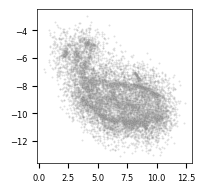

In [79]:
#x_proj = TSNE(perplexity=1000).fit_transform(X_input)
x_proj = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors = 1000).fit_transform(X_input)
plt.figure(figsize=(2,2))
sns.scatterplot( x= x_proj[:,0], y = x_proj[:,1] ,s = 2, color='gray',alpha = .25)